<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS14_Implementasi_Dataset_Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    Flatten, Dense, Dropout, GaussianNoise
)
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Sleep_health_and_lifestyle_dataset(1).csv to Sleep_health_and_lifestyle_dataset(1).csv


In [3]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset(1).csv')

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [4]:
print("Ukuran Dataset:", df.shape)

print("\nInformasi Dataset:")
df.info()

print("\nJumlah Data Kosong:")
print(df.isnull().sum())

print("\nData Sleep Disorder:")
print(df['Sleep Disorder'].value_counts(dropna=False))

Ukuran Dataset: (374, 13)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)

In [5]:
# Mengubah nilai None menjadi No Disorder
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('No Disorder')

# Membuat target klasifikasi biner
df['Target'] = df['Sleep Disorder'].apply(
    lambda x: 0 if x == 'No Disorder' else 1
)

# Memisahkan fitur dan target
X = df.drop(columns=['Person ID', 'Sleep Disorder', 'Target'])
y = df['Target']

print("Jumlah fitur:", X.shape[1])
print("\nDistribusi Target:")
print(y.value_counts())

Jumlah fitur: 11

Distribusi Target:
Target
0    219
1    155
Name: count, dtype: int64


In [6]:
# Mengubah Blood Pressure menjadi dua fitur numerik
X[['Systolic BP', 'Diastolic BP']] = (
    X['Blood Pressure']
    .str.split('/', expand=True)
    .astype(float)
)

X = X.drop(columns=['Blood Pressure'])

# Menentukan kolom kategorikal
categorical_features = [
    'Gender',
    'Occupation',
    'BMI Category'
]

# Menentukan kolom numerik
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Fitur Kategorikal:", categorical_features)
print("Fitur Numerik:", numerical_features)

Fitur Kategorikal: ['Gender', 'Occupation', 'BMI Category']
Fitur Numerik: ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic BP', 'Diastolic BP']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training:", X_train.shape[0])
print("Jumlah Data Testing:", X_test.shape[0])

Jumlah Data Training: 299
Jumlah Data Testing: 75


In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Mengubah hasil menjadi array
X_train_processed = X_train_processed.astype('float32')
X_test_processed = X_test_processed.astype('float32')

print("Shape Training:", X_train_processed.shape)
print("Shape Testing:", X_test_processed.shape)

Shape Training: (299, 25)
Shape Testing: (75, 25)


In [9]:
# CNN 1D membutuhkan format:
# (jumlah data, jumlah fitur, jumlah channel)

X_train_cnn = np.expand_dims(X_train_processed, axis=2)
X_test_cnn = np.expand_dims(X_test_processed, axis=2)

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Shape X Training:", X_train_cnn.shape)
print("Shape X Testing:", X_test_cnn.shape)

Shape X Training: (299, 25, 1)
Shape X Testing: (75, 25, 1)


In [10]:
cnn = Sequential()

cnn.add(Input(shape=(X_train_cnn.shape[1], 1)))

# Convolutional Layer pertama
cnn.add(Conv1D(
    filters=32,
    kernel_size=3,
    activation='relu',
    padding='same'
))

# Pooling Layer pertama
cnn.add(MaxPooling1D(pool_size=2))

# Convolutional Layer kedua
cnn.add(Conv1D(
    filters=32,
    kernel_size=3,
    activation='relu',
    padding='same'
))

# Pooling Layer kedua
cnn.add(MaxPooling1D(pool_size=2))

# Mengubah output menjadi satu dimensi
cnn.add(Flatten())

# Fully Connected Layer
cnn.add(Dense(units=128, activation='relu'))

cnn.add(Dropout(0.3))

# Output Layer
cnn.add(Dense(units=1, activation='sigmoid'))

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 25, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 12, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 6, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,065 (109.63 KB)

 Trainable params: 28,065 (109.63 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model berhasil dikompilasi!")

Model berhasil dikompilasi!


In [12]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = cnn.fit(
    X_train_cnn,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7113 - loss: 0.6052 - val_accuracy: 0.9333 - val_loss: 0.4808
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9331 - loss: 0.3889 - val_accuracy: 0.9333 - val_loss: 0.3248
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9372 - loss: 0.2767 - val_accuracy: 0.9333 - val_loss: 0.2859
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9372 - loss: 0.2564 - val_accuracy: 0.9333 - val_loss: 0.2802
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9331 - loss: 0.2579 - val_accuracy: 0.9167 - val_loss: 0.2782
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9331 - loss: 0.2395 - val_accuracy: 0.9167 - val_loss: 0.2838
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9414 - loss: 0.2467 - val_accuracy: 0.9333 - val_loss: 0.2754
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9372 - loss: 0.2382 - val_accuracy: 0.9167 - va

In [13]:
loss, accuracy = cnn.evaluate(X_test_cnn, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9067 - loss: 0.2634
Test Loss: 0.2633810043334961
Test Accuracy: 0.9066666960716248
Test Accuracy (%): 90.66666960716248


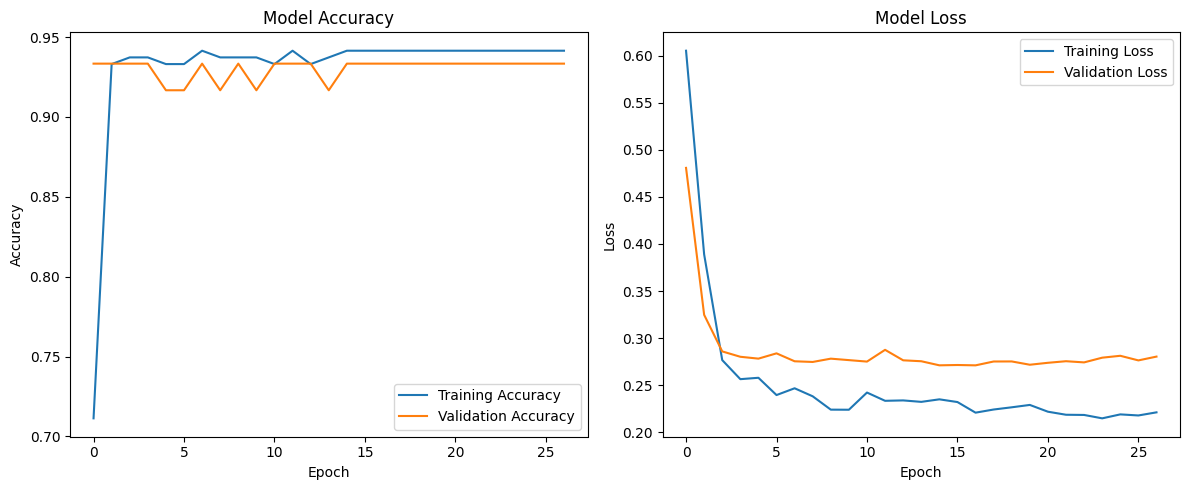

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Classification Report:
                precision    recall  f1-score   support

   No Disorder       0.95      0.89      0.92        44
Sleep Disorder       0.85      0.94      0.89        31

      accuracy                           0.91        75
     macro avg       0.90      0.91      0.90        75
  weighted avg       0.91      0.91      0.91        75



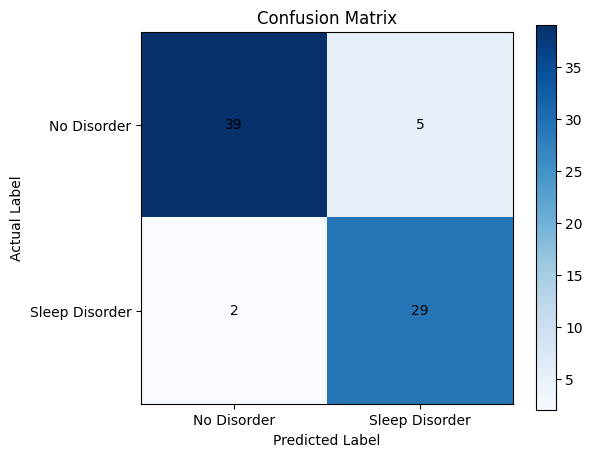

In [15]:
y_pred = cnn.predict(X_test_cnn)

y_pred_class = (y_pred >= 0.5).astype(int).flatten()

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_class,
    target_names=['No Disorder', 'Sleep Disorder']
))

cm = confusion_matrix(y_test, y_pred_class)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.xticks([0, 1], ['No Disorder', 'Sleep Disorder'])
plt.yticks([0, 1], ['No Disorder', 'Sleep Disorder'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

In [16]:
# Mengambil satu data dari dataset testing
sample = X_test.iloc[[0]]

# Melakukan preprocessing
sample_processed = preprocessor.transform(sample)

# Mengubah format menjadi CNN 1D
sample_cnn = np.expand_dims(
    sample_processed.astype('float32'),
    axis=2
)

# Melakukan prediksi
prediction = cnn.predict(sample_cnn)

if prediction[0][0] >= 0.5:
    print("Hasil Prediksi: Sleep Disorder")
else:
    print("Hasil Prediksi: No Disorder")

print("Nilai Prediksi:", prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Hasil Prediksi: Sleep Disorder
Nilai Prediksi: 0.91211474
